# Capstone — mirrors your deployed research paper

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/dharshinianand19/FlyRank-Starters/blob/main/work/notebooks/capstone.ipynb?flush_cache=true)

This skeleton is yours to fill. Work the sections **in order** — each one has a one-line hint. Simple words, honest numbers.

> Working with an AI assistant? Tell it to read `skills/README.md` first and load the one skill this assignment names on its card.

## 1. Question

*The research question and the decision it supports.*

## 2. Data

*Which release, which tables, date windows, what you excluded and why. Public-safe.*

Data Source and Preparation
Dataset Release

This project uses the FlyRank Internship — Pseudonymized Warehouse Release (v20260703), a frozen warehouse snapshot exported on July 3, 2026.
Tables Used

    dim_content: content metadata, including content type, creation and update dates, word count, search volume, and publication status.
    fact_content_daily_performance: daily performance metrics, including impressions, clicks, average search position, pageviews, and sessions.

The warehouse provides monthly performance partitions from January 2025 through June 2026. The sample file was used for initial schema inspection.
Date Windows

The final training, validation, and test windows will be specified in the methodology and evaluation sections. They will be selected to preserve temporal order and avoid using future information as a model input.
Exclusions and Data Safety

Pseudonymous client, content, keyword, and URL identifiers will not be used as predictive features. Client-identifying information, URLs, and private queries will not appear in public outputs. Label-derived fields, including trend_direction and trend_pct, will be excluded from model inputs. Features will be restricted to information available at the prediction time, and unavailable performance data will not automatically be treated as zero performance.

In [3]:
%pip -q install duckdb huggingface_hub pandas pyarrow

In [5]:
from huggingface_hub import notebook_login
notebook_login()

In [6]:
from huggingface_hub import HfApi
api = HfApi()
try:
    info = api.dataset_info("FlyRank/internship-warehouse")
    print("Dataset metadata is accessible!")
    print("Dataset ID:", info.id)
    print("Private/gated:", info.private, info.gated)
except Exception as e:
    print("Dataset access check failed.")
    print("Error:", str(e)[:500])

Dataset metadata is accessible!
Dataset ID: FlyRank/internship-warehouse
Private/gated: False auto


In [7]:
from huggingface_hub import HfApi
api = HfApi()
files = api.list_repo_files(
    repo_id="FlyRank/internship-warehouse",
    repo_type="dataset"
)
print("Available dataset files:\n")
for file in files:
    print(file)

Available dataset files:

.gitattributes
README.md
dim_clients.parquet
dim_content.parquet
fact_content_daily_performance/month=2025-01/data_0.parquet
fact_content_daily_performance/month=2025-02/data_0.parquet
fact_content_daily_performance/month=2025-03/data_0.parquet
fact_content_daily_performance/month=2025-04/data_0.parquet
fact_content_daily_performance/month=2025-05/data_0.parquet
fact_content_daily_performance/month=2025-06/data_0.parquet
fact_content_daily_performance/month=2025-07/data_0.parquet
fact_content_daily_performance/month=2025-08/data_0.parquet
fact_content_daily_performance/month=2025-09/data_0.parquet
fact_content_daily_performance/month=2025-10/data_0.parquet
fact_content_daily_performance/month=2025-11/data_0.parquet
fact_content_daily_performance/month=2025-12/data_0.parquet
fact_content_daily_performance/month=2026-01/data_0.parquet
fact_content_daily_performance/month=2026-02/data_0.parquet
fact_content_daily_performance/month=2026-03/data_0.parquet
fact_cont

In [8]:
from huggingface_hub import HfApi
from huggingface_hub.utils import get_token
token = get_token()

if not token:
    print("No saved token found. We need to log in again.")
else:
    try:
        api = HfApi(token=token)
        user = api.whoami()
        print("Hugging Face login works.")
        print("Authenticated account:", user.get("name", "verified"))

        info = api.get_paths_info(
            repo_id="FlyRank/internship-warehouse",
            paths=["fact_content_daily_performance_sample.parquet"],
            repo_type="dataset",
        )
        print("Sample file metadata accessible:", bool(info))

    except Exception as e:
        print("Access check failed:", str(e)[:300])


Hugging Face login works.
Authenticated account: dharshinia
Sample file metadata accessible: True


In [9]:
from huggingface_hub import hf_hub_download, get_token
import pandas as pd

print("Downloading the sample file...")

sample_file = hf_hub_download(
    repo_id="FlyRank/internship-warehouse",
    filename="fact_content_daily_performance_sample.parquet",
    repo_type="dataset",
    token=get_token()
)

print("Sample file ready!")

# Inspect the schema
sample_schema = pd.read_parquet(sample_file).head(5)
print("\nColumns:")
print(sample_schema.columns.tolist())

print("\nData types:")
print(sample_schema.dtypes)

print("\nFirst 5 rows:")
display(sample_schema)

fact_content_daily_performance_sample.pa(…): reconstructing file:   0%|          |  0.00B /  145MB            

fact_content_daily_performance_sample.pa(…): downloading bytes:           |  0.00B            

Sample file ready!

Columns:
['report_date', 'client_hash_id', 'content_hash_id', 'client_has_gsc', 'client_has_ga4', 'gsc_data_available', 'ga4_data_available', 'gsc_impressions', 'gsc_clicks', 'gsc_sum_position', 'gsc_avg_position', 'ga4_pageviews', 'ga4_sessions', 'ga4_users', 'ga4_engaged_sessions', 'ga4_total_engagement_sec', 'sessions_organic', 'sessions_direct', 'sessions_referral', 'sessions_social', 'sessions_paid', 'sessions_ai', 'ai_chatgpt', 'ai_perplexity', 'ai_gemini', 'ai_copilot', 'ai_claude', 'ai_meta', 'ai_other', 'scroll_events', 'month']

Data types:
report_date                  object
client_hash_id               object
content_hash_id              object
client_has_gsc                 bool
client_has_ga4                 bool
gsc_data_available             bool
ga4_data_available           object
gsc_impressions               int64
gsc_clicks                    int64
gsc_sum_position            float64
gsc_avg_position            float64
ga4_pageviews              

,report_date,client_hash_id,content_hash_id,client_has_gsc,client_has_ga4,gsc_data_available,ga4_data_available,gsc_impressions,gsc_clicks,gsc_sum_position,...,sessions_ai,ai_chatgpt,ai_perplexity,ai_gemini,ai_copilot,ai_claude,ai_meta,ai_other,scroll_events,month
0,2026-06-01,client_3ffa76342f366962,content_1a6296faee432dae,True,True,False,False,0,0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2026-06
1,2026-06-01,client_3ffa76342f366962,content_73f21e612565035a,True,True,False,False,0,0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2026-06
2,2026-06-01,client_3ffa76342f366962,content_5a5be514ff559598,True,True,False,False,0,0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2026-06
3,2026-06-01,client_3ffa76342f366962,content_05b377d0c8a5cfd8,True,True,False,False,0,0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2026-06
4,2026-06-01,client_3ffa76342f366962,content_dc34c661d63e55a9,True,True,False,False,0,0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2026-06


In [10]:
from huggingface_hub import hf_hub_download, get_token
import pandas as pd

content_file = hf_hub_download(
    repo_id="FlyRank/internship-warehouse",
    filename="dim_content.parquet",
    repo_type="dataset",
    token=get_token()
)

content = pd.read_parquet(content_file)

print("Shape:", content.shape)
print("\nColumns:")
print(content.dtypes.to_string())
print("\nFirst 3 rows:")
display(content.head(3))

dim_content.parquet: reconstructing file:   0%|          |  0.00B / 19.6MB            

dim_content.parquet: downloading bytes:           |  0.00B            

Shape: (519606, 26)

Columns:
client_hash_id                 object
content_hash_id                object
keyword_hash_id                object
url_hash_id                    object
keyword_char_count              int64
keyword_token_count             int64
url_char_count                  int64
content_created_date           object
content_updated_date           object
content_type                   object
search_volume                 float64
competition                   float64
competition_level              object
cpc                           float64
main_intent                    object
backlinks                     float64
category_count                  int64
keyword_created_date           object
provider_used                  object
model_used                     object
char_count                    float64
word_count                    float64
last_optimized_date            object
optimization_eligible_date     object
is_published                     bool
is_deleted          

,client_hash_id,content_hash_id,keyword_hash_id,url_hash_id,keyword_char_count,keyword_token_count,url_char_count,content_created_date,content_updated_date,content_type,...,category_count,keyword_created_date,provider_used,model_used,char_count,word_count,last_optimized_date,optimization_eligible_date,is_published,is_deleted
0,client_04660893ae39614a,content_004de9653278b5a4,keyword_e754999ab88dd9f2,url_d6091f18cf628794,22,4,108,2026-05-30,2026-07-01,keyword article,...,3,2026-05-12,gemini-generate-content,gemini-3-flash-preview,15682.0,2555.0,None,None,True,False
1,client_04660893ae39614a,content_00dc5efae381b2ab,keyword_4329d7aede8e208b,url_3a66d2f2e36823ca,31,6,95,2026-06-12,2026-07-01,keyword article,...,4,2026-06-01,gemini-generate-content,gemini-3-flash-preview,15438.0,2430.0,None,None,True,False
2,client_04660893ae39614a,content_01410f2556c327ac,keyword_9b08047d3d2a0406,url_809eda7a7e20b3b2,22,5,82,2026-05-09,2026-07-01,keyword article,...,4,2026-05-06,gemini-generate-content,gemini-3-flash-preview,16576.0,2645.0,None,None,True,False


## 3. Methodology

*Assumptions, features, label definition, baseline, validation design, leakage checks.*

Methodology
Approach

This project compares a transparent rule-based baseline with a machine learning model for prioritizing content items for review.
Features

Candidate features include content age, word count, content type, and historical search-performance metrics such as impressions, clicks, and average position. Pseudonymous identifiers will be used only for joins or grouping, never as predictive features.
Target Definition

The target will be defined from a subsequent reporting period's observed performance change, if the available data supports a reliable time-based comparison. The exact target and threshold will be documented before model training.
Baseline

The Week 4 rule-based score will serve as the baseline. The machine learning model must be evaluated on the same eligible records and evaluation split.
Validation and Leakage Prevention

Training and evaluation will respect time order. Features will use only information available before the target period. Fields derived from the target period, including trend_direction and trend_pct, will not be used as model inputs. The final test period will be kept separate from model selection.
Evaluation

Model and baseline performance will be compared using suitable metrics, including the target's base rate and a discrimination metric where appropriate. Results will be reported as observed predictive performance, not evidence that refreshing content causes improvement.

In [11]:
# Checking the reporting dates and coverage in the sample already downloaded
sample_df = pd.read_parquet(sample_file)

sample_df["report_date"] = pd.to_datetime(sample_df["report_date"])

print("Sample date range:",
      sample_df["report_date"].min().date(),
      "to",
      sample_df["report_date"].max().date())

print("\nRows by month:")
print(sample_df.groupby("month").size().to_string())

print("\nPerformance availability:")
print(sample_df[
    ["gsc_data_available", "ga4_data_available"]
].astype(str).apply(lambda col: col.value_counts()).fillna(0).to_string())

Sample date range: 2026-06-01 to 2026-06-30

Rows by month:
month
2026-06    11694072

Performance availability:
       gsc_data_available  ga4_data_available
False           7815135.0             8651918
None                  0.0             2397428
True            3878937.0              644726


In [12]:
from huggingface_hub import hf_hub_download, get_token
import pandas as pd

march_file = hf_hub_download(
    repo_id="FlyRank/internship-warehouse",
    filename="fact_content_daily_performance/month=2026-03/data_0.parquet",
    repo_type="dataset",
    token=get_token()
)

march_df = pd.read_parquet(march_file)

print("March rows and columns:", march_df.shape)
print("Date range:",
      pd.to_datetime(march_df["report_date"]).min().date(),
      "to",
      pd.to_datetime(march_df["report_date"]).max().date())
print("Columns:", march_df.columns.tolist())

fact_content_daily_performance/month=202(…): reconstructing file:   0%|          |  0.00B /  124MB            

fact_content_daily_performance/month=202(…): downloading bytes:           |  0.00B            

March rows and columns: (9841378, 30)
Date range: 2026-03-01 to 2026-03-31
Columns: ['report_date', 'client_hash_id', 'content_hash_id', 'client_has_gsc', 'client_has_ga4', 'gsc_data_available', 'ga4_data_available', 'gsc_impressions', 'gsc_clicks', 'gsc_sum_position', 'gsc_avg_position', 'ga4_pageviews', 'ga4_sessions', 'ga4_users', 'ga4_engaged_sessions', 'ga4_total_engagement_sec', 'sessions_organic', 'sessions_direct', 'sessions_referral', 'sessions_social', 'sessions_paid', 'sessions_ai', 'ai_chatgpt', 'ai_perplexity', 'ai_gemini', 'ai_copilot', 'ai_claude', 'ai_meta', 'ai_other', 'scroll_events']


In [13]:
from huggingface_hub import hf_hub_download, get_token
import duckdb
import pandas as pd

months = ["2026-03", "2026-04", "2026-05", "2026-06"]
paths = {"2026-03": march_file}

for month in months[1:]:
    paths[month] = hf_hub_download(
        repo_id="FlyRank/internship-warehouse",
        filename=f"fact_content_daily_performance/month={month}/data_0.parquet",
        repo_type="dataset",
        token=get_token()
    )

con = duckdb.connect()
monthly_parts = []

for month, path in paths.items():
    result = con.execute("""
        SELECT
            client_hash_id,
            content_hash_id,
            AVG(gsc_impressions) AS avg_daily_impressions,
            AVG(gsc_clicks) AS avg_daily_clicks,
            AVG(gsc_avg_position) AS avg_position,
            COUNT(*) AS available_days
        FROM read_parquet(?)
        WHERE gsc_data_available = TRUE
        GROUP BY client_hash_id, content_hash_id
        HAVING COUNT(*) >= 15
    """, [path]).df()

    result["month"] = month
    monthly_parts.append(result)
    print(f"{month}: {len(result):,} content records with sufficient GSC data")

monthly = pd.concat(monthly_parts, ignore_index=True)
print("\nMonthly aggregates prepared:", monthly.shape)

fact_content_daily_performance/month=202(…): reconstructing file:   0%|          |  0.00B /  134MB            

fact_content_daily_performance/month=202(…): downloading bytes:           |  0.00B            

fact_content_daily_performance/month=202(…): reconstructing file:   0%|          |  0.00B /  149MB            

fact_content_daily_performance/month=202(…): downloading bytes:           |  0.00B            

fact_content_daily_performance/month=202(…): reconstructing file:   0%|          |  0.00B /  146MB            

fact_content_daily_performance/month=202(…): downloading bytes:           |  0.00B            

... (2 outputs left out)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

2026-05: 141,600 content records with sufficient GSC data


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

2026-06: 127,815 content records with sufficient GSC data

Monthly aggregates prepared: (518305, 7)


In [14]:
import numpy as np
import pandas as pd

# Pairing each month's performance with the following month's outcome
pairs = []

for current_month, next_month in [
    ("2026-03", "2026-04"),
    ("2026-04", "2026-05"),
    ("2026-05", "2026-06"),
]:
    current = monthly[monthly["month"] == current_month].copy()
    future = monthly[monthly["month"] == next_month].copy()

    current = current.rename(columns={
        "avg_daily_impressions": "current_impressions",
        "avg_daily_clicks": "current_clicks",
        "avg_position": "current_position",
        "available_days": "current_available_days",
    })

    future = future.rename(columns={
        "avg_daily_impressions": "future_impressions"
    })

    pair = current.merge(
        future[
            ["client_hash_id", "content_hash_id", "future_impressions"]
        ],
        on=["client_hash_id", "content_hash_id"],
        how="inner"
    )

    # Target: at least 20% decline in next month's impressions
    pair = pair[pair["current_impressions"] > 0].copy()
    pair["decline_next_month"] = (
        pair["future_impressions"] <= 0.8 * pair["current_impressions"]
    ).astype(int)

    pair["feature_month"] = current_month
    pairs.append(pair)

model_data = pd.concat(pairs, ignore_index=True)

print("Matched content-month pairs:", f"{len(model_data):,}")
print("\nTarget rate by feature month:")
print(model_data.groupby("feature_month")["decline_next_month"].agg(
    records="size",
    decline_rate="mean"
).to_string())

Matched content-month pairs: 338,853

Target rate by feature month:
               records  decline_rate
feature_month                       
2026-03         108027      0.477621
2026-04         117490      0.510775
2026-05         113336      0.583230


## 4. Results (vs baseline)

*Model vs baseline on the same split. The honest table.*

In [15]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, average_precision_score
)
import pandas as pd
import numpy as np

# Features available in the current month only
features = [
    "current_impressions",
    "current_clicks",
    "current_position",
    "current_available_days",
]

train = model_data[model_data["feature_month"].isin(["2026-03", "2026-04"])].copy()
test = model_data[model_data["feature_month"] == "2026-05"].copy()

X_train, y_train = train[features], train["decline_next_month"]
X_test, y_test = test[features], test["decline_next_month"]

model = make_pipeline(
    SimpleImputer(strategy="median"),
    StandardScaler(),
    LogisticRegression(max_iter=500, class_weight="balanced", random_state=42)
)
model.fit(X_train, y_train)

probs = model.predict_proba(X_test)[:, 1]
preds = (probs >= 0.5).astype(int)

# Majority-class baseline
majority_pred = np.full(len(y_test), int(y_train.mean() >= 0.5))

def metrics(name, actual, predicted, score=None):
    result = {
        "Model": name,
        "Accuracy": accuracy_score(actual, predicted),
        "Precision": precision_score(actual, predicted, zero_division=0),
        "Recall": recall_score(actual, predicted, zero_division=0),
        "F1": f1_score(actual, predicted, zero_division=0),
    }
    if score is not None:
        result["ROC_AUC"] = roc_auc_score(actual, score)
        result["Avg_Precision"] = average_precision_score(actual, score)
    return result

results = pd.DataFrame([
    metrics("Majority baseline", y_test, majority_pred),
    metrics("Logistic regression", y_test, preds, probs),
])

print("Training rows:", len(train))
print("Test rows:", len(test))
print("Test decline base rate:", round(y_test.mean(), 4))
display(results.round(4))


Training rows: 225517
Test rows: 113336
Test decline base rate: 0.5832


,Model,Accuracy,Precision,Recall,F1,ROC_AUC,Avg_Precision
0,Majority baseline,0.4168,0.0000,0.0000,0.000,NaN,NaN
1,Logistic regression,0.6093,0.6414,0.7489,0.691,0.6004,0.654


In [16]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, average_precision_score
)
import numpy as np
import pandas as pd

# Positive class = decline_next_month == 1
majority_class = int(y_train.mean() >= 0.5)
baseline_preds = np.full(len(y_test), majority_class)

print("Training decline rate:", round(y_train.mean(), 4))
print("Test decline rate:", round(y_test.mean(), 4))
print("Majority class predicted:", majority_class)

print("\nMajority baseline")
print("Accuracy:", round(accuracy_score(y_test, baseline_preds), 4))
print("Precision:", round(precision_score(y_test, baseline_preds, zero_division=0), 4))
print("Recall:", round(recall_score(y_test, baseline_preds, zero_division=0), 4))
print("F1:", round(f1_score(y_test, baseline_preds, zero_division=0), 4))

print("\nLogistic regression")
print("Accuracy:", round(accuracy_score(y_test, preds), 4))
print("Precision:", round(precision_score(y_test, preds, zero_division=0), 4))
print("Recall:", round(recall_score(y_test, preds, zero_division=0), 4))
print("F1:", round(f1_score(y_test, preds, zero_division=0), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, probs), 4))
print("Average precision:", round(average_precision_score(y_test, probs), 4))

Training decline rate: 0.4949
Test decline rate: 0.5832
Majority class predicted: 0

Majority baseline
Accuracy: 0.4168
Precision: 0.0
Recall: 0.0
F1: 0.0

Logistic regression
Accuracy: 0.6093
Precision: 0.6414
Recall: 0.7489
F1: 0.691
ROC-AUC: 0.6004
Average precision: 0.654


In [17]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Simple transparent baseline: low current impressions -> likely decline
threshold = train["current_impressions"].median()
rule_preds = (X_test["current_impressions"] < threshold).astype(int)

comparison = pd.DataFrame([
    {
        "Model": "Low-impressions rule",
        "Accuracy": accuracy_score(y_test, rule_preds),
        "Precision": precision_score(y_test, rule_preds, zero_division=0),
        "Recall": recall_score(y_test, rule_preds, zero_division=0),
        "F1": f1_score(y_test, rule_preds, zero_division=0),
    },
    {
        "Model": "Logistic regression",
        "Accuracy": accuracy_score(y_test, preds),
        "Precision": precision_score(y_test, preds, zero_division=0),
        "Recall": recall_score(y_test, preds, zero_division=0),
        "F1": f1_score(y_test, preds, zero_division=0),
    }
])

display(comparison.round(4))

,Model,Accuracy,Precision,Recall,F1
0,Low-impressions rule,0.4397,0.5215,0.4777,0.4986
1,Logistic regression,0.6093,0.6414,0.7489,0.6910


## 5. Limitations

*What this work cannot claim.*


While Logistic Regression outperformed both baselines, its predictions serve as directional signals for prioritization rather than definitive conclusions.

**1. Moderate predictive discrimination**

* **Limitation:** An ROC-AUC of 0.6004 (F1: 0.6910) shows limited separation between declining and non-declining content.
* **Solution:** Benchmark Random Forest and Gradient Boosting on the same temporal split using ROC-AUC, Average Precision, precision, recall, and F1.

**2. Limited evaluation period**

* **Limitation:** Training on March–April 2026 and testing on May–June 2026 yields only one test month, limiting seasonal generalizability.
* **Solution:** Use rolling time-based validation across multiple months while retaining a strictly held-out final test period.

**3. Possible repeated-content overlap**

* **Limitation:** The temporal split allows the same content items to appear in both train and test sets, masking performance on unseen content.
* **Solution:** Run a content-grouped split for unseen items, and evaluate across held-out clients if deploying to new accounts.

**4. Dependence on search data availability**

* **Limitation:** Requiring at least 15 days of Google Search Console data excludes low-volume or unindexed items, reducing warehouse representativeness.
* **Solution:** Track missingness explicitly, evaluate performance across data-availability tiers, and avoid treating missing metrics as zeros.

**5. Narrow target definition**

* **Limitation:** Defining decline as a ≥20% drop in next-month average daily impressions does not prove content decay or guarantee that a refresh will help.
* **Solution:** Use predictions as early-warning flags alongside editorial review, content freshness, and search intent.

**6. Fixed threshold and probability calibration**

* **Limitation:** The default 0.5 threshold may not balance false negatives and review costs, and class weighting can distort probability calibration.
* **Solution:** Tune thresholds via precision-recall curves aligned with editorial capacity, and calibrate probabilities before using them as risk scores.

**7. Limited feature coverage**

* **Limitation:** The model relies solely on current impressions, clicks, average position, and reporting days—omitting content age, format, word count, and historical trends.
* **Solution:** Test leak-free pre-prediction features on validation data and retain only those that measurably improve performance.

## 6. Ranked recommendations

*The action playbook output — the paper's recommendations section.*

## 6. Ranked Recommendations

The Logistic Regression model predicts whether a content item will see a ≥20% drop in average daily impressions next month (test recall: **74.89%**, precision: **64.14%**). FlyRank editors should triage content into three priority tiers based on predicted decline probability:

**Priority 1: High-Risk Content (Immediate Review)**

* **Audit performance:** Inspect recent impressions, clicks, and average search position shifts to separate temporary dips from sustained drops.
* **Assess relevance:** Check for outdated information or search-intent drift, and refresh only when editorial evidence supports it.

**Priority 2: Moderate-Risk Content (Secondary Queue)**

* **Verify & track:** Confirm sufficient reporting data availability before interpreting month-over-month click and impression drops.
* **Spot-check freshness:** Flag potential relevance or freshness gaps for upcoming editorial cycles.

**Priority 3: Lower-Risk Content (Routine Monitoring)**

* **Maintain & re-evaluate:** Track monthly metrics passively, avoid unnecessary edits, and reassess in future reporting runs.

**Operational & Confidence Guidelines**

* **Rank by probability:** Sort queues by predicted decline probability and cap intake using a Top-K limit aligned with editorial capacity.
* **Treat as signals, not mandates:** While the model outperforms majority-class and low-impression baselines, its modest ROC-AUC (**0.6004**) requires human verification before updating pages.
* **Validate impact:** Run a controlled A/B refresh experiment against unrefreshed comparable pages to measure true lift, and re-evaluate model performance across future reporting periods.


In [18]:

# ==========================================
# RANKED CONTENT RECOMMENDATIONS
# ==========================================

import numpy as np
import pandas as pd
from pathlib import Path

# Copy test records
ranked = test.copy()

# Add predicted probability of decline
ranked["decline_probability"] = probs

# Sort by predicted probability
ranked = ranked.sort_values(
    "decline_probability",
    ascending=False
).reset_index(drop=True)

# Assign rank
ranked["rank"] = range(1, len(ranked) + 1)

# Define review capacity
n = len(ranked)

high_limit = int(np.ceil(n * 0.10))
medium_limit = int(np.ceil(n * 0.30))

# Assign recommendations
ranked["recommendation"] = np.select(
    [
        ranked["rank"] <= high_limit,
        ranked["rank"] <= medium_limit
    ],
    [
        "high_priority_review",
        "investigate"
    ],
    default="monitor"
)

# Add explanation
ranked["reason"] = np.select(
    [
        ranked["recommendation"] == "high_priority_review",
        ranked["recommendation"] == "investigate"
    ],
    [
        "Highest predicted decline risk",
        "Moderate relative predicted decline risk"
    ],
    default="Lower relative predicted decline risk"
)

# Select output columns
output_columns = [
    "rank",
    "content_hash_id",
    "decline_probability",
    "recommendation",
    "reason",
    "current_impressions",
    "current_clicks",
    "current_position",
    "current_available_days",
    "decline_next_month"
]

# Save ranked output
output_dir = Path("/content/work/outputs")
output_dir.mkdir(parents=True, exist_ok=True)

ranked_path = output_dir / "ranked_content_recommendations.csv"

ranked[output_columns].to_csv(
    ranked_path,
    index=False
)

# Display results
print("Total test records:", n)

print("\nRecommendation distribution:")
print(ranked["recommendation"].value_counts())

print("\nTop 20 recommendations:")
display(ranked[output_columns].head(20))

print("\nSaved to:", ranked_path)


Total test records: 113336

Recommendation distribution:
recommendation
monitor                 79335
investigate             22667
high_priority_review    11334
Name: count, dtype: int64

Top 20 recommendations:


,rank,content_hash_id,decline_probability,recommendation,reason,current_impressions,current_clicks,current_position,current_available_days,decline_next_month
0,1,content_33d31496fca9665e,0.993607,high_priority_review,Highest predicted decline risk,7607.000000,1.451613,5.729751,31,1
1,2,content_9648c4d1595a0794,0.990202,high_priority_review,Highest predicted decline risk,7096.193548,1.677419,2.576378,31,1
2,3,content_39e19a3ec2d95f9d,0.989776,high_priority_review,Highest predicted decline risk,6106.387097,0.064516,10.083081,31,1
3,4,content_65c75874a23fca87,0.984423,high_priority_review,Highest predicted decline risk,6179.548387,1.032258,14.603478,31,1
4,5,content_c60628276389acbb,0.967329,high_priority_review,Highest predicted decline risk,5193.000000,0.225806,59.325645,31,1
5,6,content_f33ad8a343180e8b,0.958260,high_priority_review,Highest predicted decline risk,4667.225806,1.064516,7.788035,31,1
6,7,content_44f34c0a90047651,0.947697,high_priority_review,Highest predicted decline risk,4410.806452,1.129032,10.661664,31,1
7,8,content_bddfdd871aa09fbe,0.943778,high_priority_review,Highest predicted decline risk,3624.290323,0.129032,7.803996,31,1
8,9,content_c1f764a2f362d1c3,0.942549,high_priority_review,Highest predicted decline risk,3837.612903,0.516129,7.698471,31,0
9,10,content_e9f2d0579387d3c3,0.917567,high_priority_review,Highest predicted decline risk,3908.580645,1.483871,8.017762,31,1



Saved to: /content/work/outputs/ranked_content_recommendations.csv


## 7. Artifacts the paper embeds

*Generate/collect the charts and tables your deployed page will show.*

,Metric,Value
0,Matched records,338853
1,Training records,225517
2,Test records,113336
3,Training decline rate,49.49
4,Test decline rate,58.32
5,Prediction threshold,20% next-month impression decline


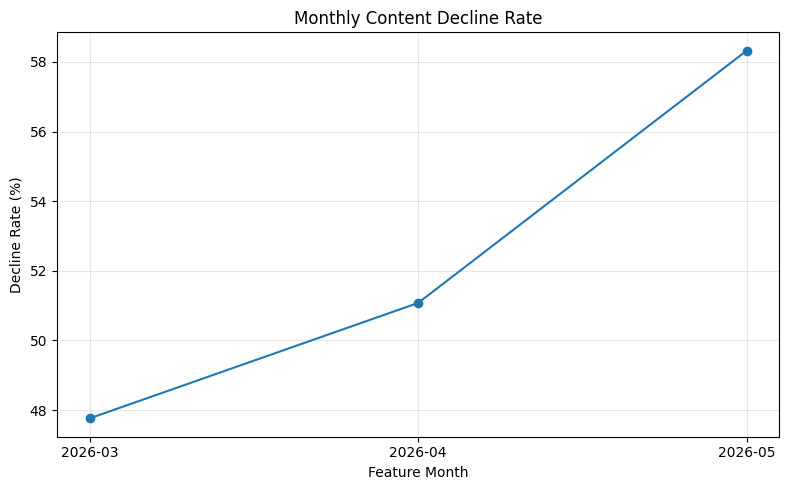

,Model,Accuracy,Precision,Recall,F1
0,Low-impressions rule,0.4397,0.5215,0.4777,0.4986
1,Logistic regression,0.6093,0.6414,0.7489,0.6910


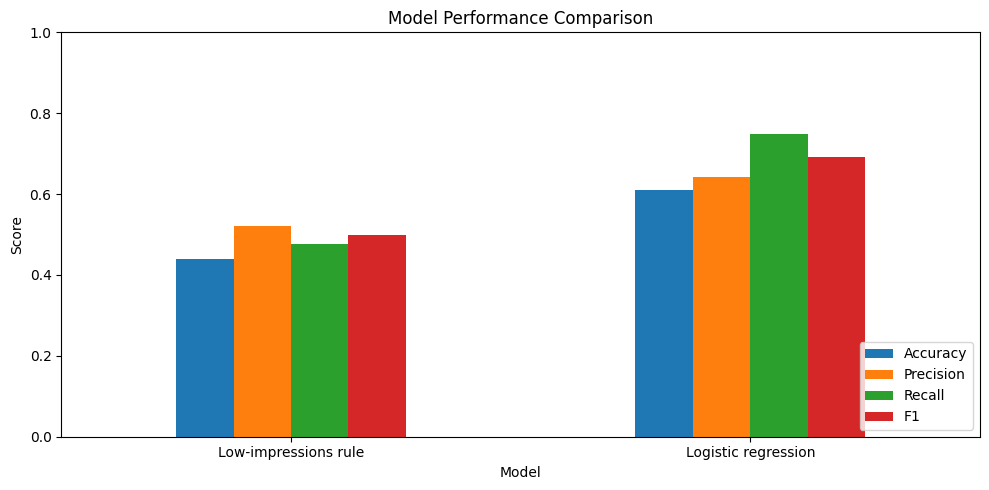

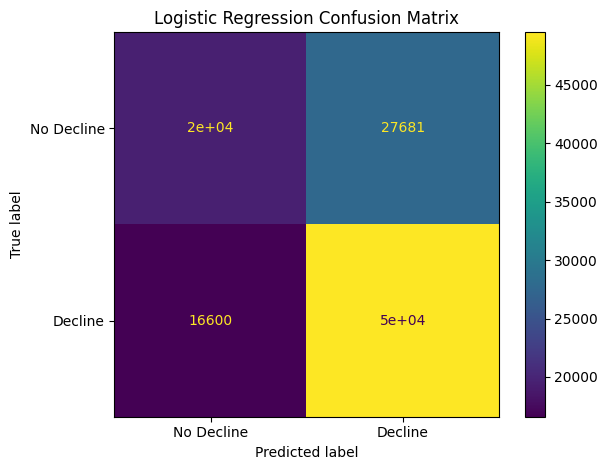

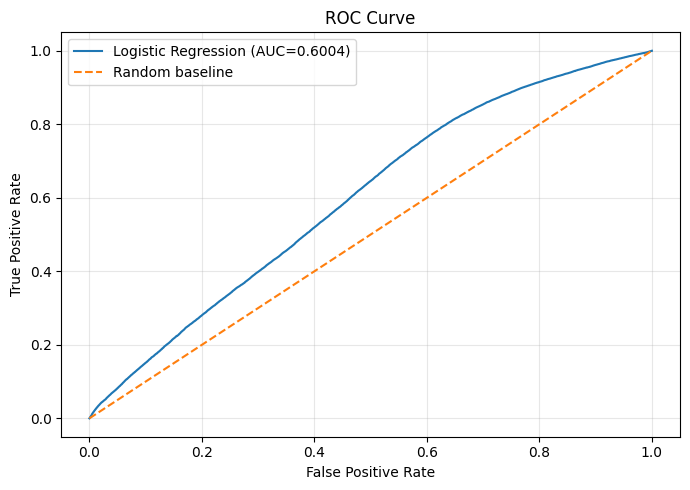

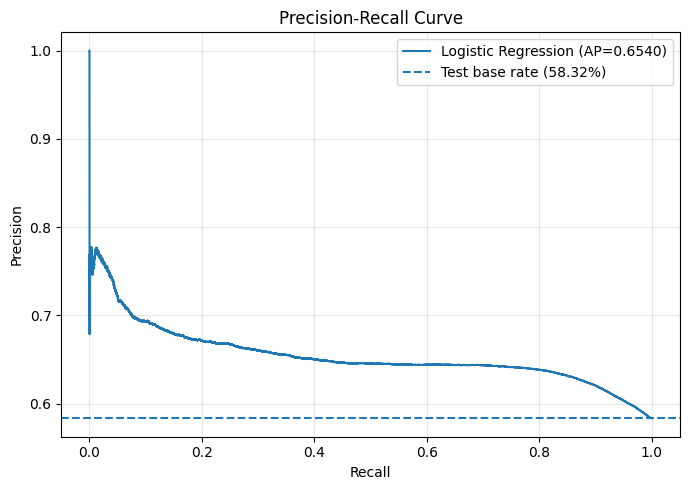

,rank,predicted_decline_probability,recommendation,current_impressions,current_clicks,current_position
0,1,99.36,High priority review,7607.000000,1.451613,5.729751
1,2,99.02,High priority review,7096.193548,1.677419,2.576378
2,3,98.98,High priority review,6106.387097,0.064516,10.083081
3,4,98.44,High priority review,6179.548387,1.032258,14.603478
4,5,96.73,High priority review,5193.000000,0.225806,59.325645
5,6,95.83,High priority review,4667.225806,1.064516,7.788035
6,7,94.77,High priority review,4410.806452,1.129032,10.661664
7,8,94.38,High priority review,3624.290323,0.129032,7.803996
8,9,94.25,High priority review,3837.612903,0.516129,7.698471
9,10,91.76,High priority review,3908.580645,1.483871,8.017762


All artifacts saved to: /content/work/artifacts
Files generated:
complete_ranked_predictions.csv
confusion_matrix.png
model_comparison.png
monthly_decline_rate.png
precision_recall_curve.png
roc_curve.png
top20_recommendations_public.csv


In [19]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve,
    precision_recall_curve,
    roc_auc_score,
    average_precision_score
)

# Output directory
artifact_dir = Path("/content/work/artifacts")
artifact_dir.mkdir(parents=True, exist_ok=True)


# ==========================================
# ARTIFACT 1: DATASET OVERVIEW
# ==========================================

overview = pd.DataFrame({
    "Metric": [
        "Matched records",
        "Training records",
        "Test records",
        "Training decline rate",
        "Test decline rate",
        "Prediction threshold"
    ],
    "Value": [
        len(model_data),
        len(train),
        len(test),
        round(y_train.mean() * 100, 2),
        round(y_test.mean() * 100, 2),
        "20% next-month impression decline"
    ]
})

display(overview)


# ==========================================
# ARTIFACT 2: MONTHLY DECLINE RATE
# ==========================================

monthly_rates = (
    model_data.groupby("feature_month")["decline_next_month"]
    .mean() * 100
)

plt.figure(figsize=(8, 5))
plt.plot(
    monthly_rates.index,
    monthly_rates.values,
    marker="o"
)

plt.title("Monthly Content Decline Rate")
plt.xlabel("Feature Month")
plt.ylabel("Decline Rate (%)")
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    artifact_dir / "monthly_decline_rate.png",
    dpi=300
)
plt.show()


# ==========================================
# ARTIFACT 3: MODEL COMPARISON
# ==========================================

model_comparison = comparison.copy()

display(model_comparison.round(4))

metrics_to_plot = ["Accuracy", "Precision", "Recall", "F1"]

model_comparison.set_index("Model")[metrics_to_plot].plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Model Performance Comparison")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.tight_layout()

plt.savefig(
    artifact_dir / "model_comparison.png",
    dpi=300
)
plt.show()


# ==========================================
# ARTIFACT 4: CONFUSION MATRIX
# ==========================================

cm = confusion_matrix(y_test, preds)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Decline", "Decline"]
)

disp.plot()
plt.title("Logistic Regression Confusion Matrix")
plt.tight_layout()

plt.savefig(
    artifact_dir / "confusion_matrix.png",
    dpi=300
)
plt.show()


# ==========================================
# ARTIFACT 5A: ROC CURVE
# ==========================================

fpr, tpr, thresholds = roc_curve(y_test, probs)
auc = roc_auc_score(y_test, probs)

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, label=f"Logistic Regression (AUC={auc:.4f})")
plt.plot([0, 1], [0, 1], linestyle="--", label="Random baseline")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    artifact_dir / "roc_curve.png",
    dpi=300
)
plt.show()


# ==========================================
# ARTIFACT 5B: PRECISION-RECALL CURVE
# ==========================================

precision_values, recall_values, thresholds = (
    precision_recall_curve(y_test, probs)
)

ap = average_precision_score(y_test, probs)
base_rate = y_test.mean()

plt.figure(figsize=(7, 5))
plt.plot(
    recall_values,
    precision_values,
    label=f"Logistic Regression (AP={ap:.4f})"
)

plt.axhline(
    base_rate,
    linestyle="--",
    label=f"Test base rate ({base_rate:.2%})"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    artifact_dir / "precision_recall_curve.png",
    dpi=300
)
plt.show()


# ==========================================
# ARTIFACT 6: TOP 20 RANKED RECOMMENDATIONS
# ==========================================

ranked = test.copy()

ranked["predicted_decline_probability"] = probs

ranked = ranked.sort_values(
    "predicted_decline_probability",
    ascending=False
).reset_index(drop=True)

ranked["rank"] = np.arange(1, len(ranked) + 1)

ranked["recommendation"] = np.select(
    [
        ranked["rank"] <= int(np.ceil(len(ranked) * 0.10)),
        ranked["rank"] <= int(np.ceil(len(ranked) * 0.30))
    ],
    [
        "High priority review",
        "Investigate"
    ],
    default="Monitor"
)

# Public-facing table: no content identifiers
top20 = ranked.head(20)[[
    "rank",
    "predicted_decline_probability",
    "recommendation",
    "current_impressions",
    "current_clicks",
    "current_position"
]].copy()

top20["predicted_decline_probability"] = (
    top20["predicted_decline_probability"] * 100
).round(2)

display(top20)

top20.to_csv(
    artifact_dir / "top20_recommendations_public.csv",
    index=False
)

# Save complete operational ranking separately
ranked.to_csv(
    artifact_dir / "complete_ranked_predictions.csv",
    index=False
)

print("All artifacts saved to:", artifact_dir)
print("Files generated:")
for file in sorted(artifact_dir.iterdir()):
    print(file.name)


## Self-check

Before you submit, confirm each line honestly:

- [ ] Every section above is filled — markdown thinking AND the code that backs it
- [ ] The notebook runs top to bottom with no errors (Runtime → Run all)
- [ ] No client names, URLs, or private queries anywhere
- [ ] My claims use careful words: observed, measured, directional, decision-support
- [ ] Committed to my repo under `work/notebooks/` — then submit your repo URL on the card. Done.
- [ ] My deployed paper has **all 9 sections** — including the **Abstract** at the top and **Acknowledgments & data credit** (the https://flyrank.ai link) at the bottom.
- [ ] **ML-12 done in this notebook's closing cells:** 5-minute demo outline + a social-post cut + a 3-sentence employer-facing summary.
